**CH.SC.U4CSE24142 - SANTHOSH A - FEATURE ENGINEERING**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    PolynomialFeatures
)
from sklearn.impute import SimpleImputer

In [ ]:
# Load Dataset
df = pd.read_csv("california_housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,NEAR BAY,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,NEAR BAY,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,NEAR BAY,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,NEAR BAY,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,NEAR BAY,342200


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   ocean_proximity     20640 non-null  object 
 9   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


In [ ]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
ocean_proximity,0
median_house_value,0


In [ ]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())
imputer = SimpleImputer(strategy="median")
df["total_bedrooms"] = imputer.fit_transform(df[["total_bedrooms"]])
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
ocean_proximity,0
median_house_value,0


In [ ]:
df["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [ ]:
df_label = df.copy()
encoder = LabelEncoder()
df_label["ocean_proximity_label"] = encoder.fit_transform(df_label["ocean_proximity"])
df_label[["ocean_proximity", "ocean_proximity_label"]].drop_duplicates()

,ocean_proximity,ocean_proximity_label
0,NEAR BAY,3
701,<1H OCEAN,0
954,INLAND,1
1850,NEAR OCEAN,4
8314,ISLAND,2


In [ ]:
df = pd.get_dummies(
    df,
    columns=["ocean_proximity"],
    drop_first=True
)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,False,False,True,False
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,False,False,True,False
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,False,False,True,False
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,False,False,True,False
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,False,False,True,False


In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
scaler = StandardScaler()
df["median_income_scaled"] = scaler.fit_transform(df[["median_income"]])
scaler = MinMaxScaler()
df["housing_median_age_scaled"] = scaler.fit_transform(df[["housing_median_age"]])
scaler = RobustScaler()
df["total_rooms_robust"] = scaler.fit_transform(df[["total_rooms"]])
df[[
    "median_income", "median_income_scaled",
    "housing_median_age", "housing_median_age_scaled",
    "total_rooms", "total_rooms_robust"
]].head()

,median_income,median_income_scaled,housing_median_age,housing_median_age_scaled,total_rooms,total_rooms_robust
0,8.3252,2.344766,41,0.784314,880,-0.733422
1,8.3014,2.332238,21,0.392157,7099,2.924276
2,7.2574,1.782699,52,1.000000,1467,-0.388178
3,5.6431,0.932968,52,1.000000,1274,-0.501691
4,3.8462,-0.012881,52,1.000000,1627,-0.294074


In [ ]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df[["rooms_per_household", "bedrooms_per_room", "population_per_household"]].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [ ]:
bins = [0, 10, 25, 40, 100]
labels = ["New", "Established", "Older", "Historic"]
df["age_group"] = pd.cut(
    df["housing_median_age"],
    bins=bins,
    labels=labels
)
df[["housing_median_age", "age_group"]].head()

,housing_median_age,age_group
0,41,Historic
1,21,Established
2,52,Historic
3,52,Historic
4,52,Historic


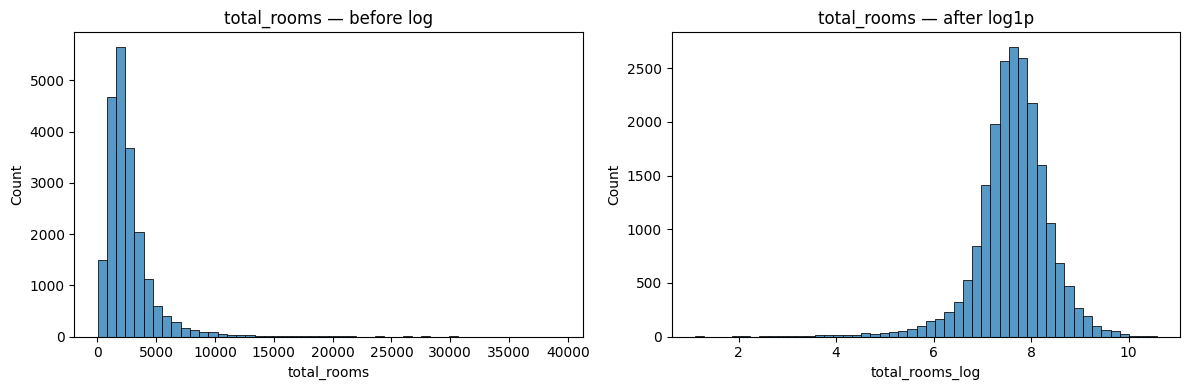

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["total_rooms"], bins=50, ax=axes[0])
axes[0].set_title("total_rooms — before log")
df["total_rooms_log"] = np.log1p(df["total_rooms"])
df["population_log"] = np.log1p(df["population"])
df["households_log"] = np.log1p(df["households"])
df["total_bedrooms_log"] = np.log1p(df["total_bedrooms"])
sns.histplot(df["total_rooms_log"], bins=50, ax=axes[1])
axes[1].set_title("total_rooms — after log1p")
plt.tight_layout()
plt.show()

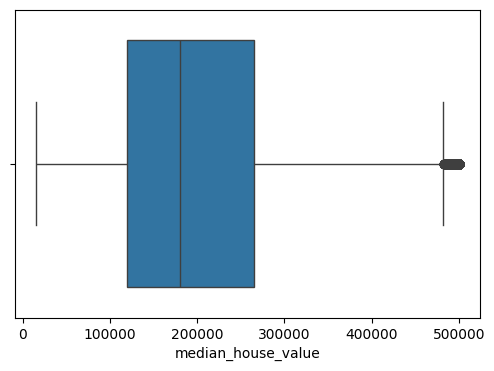

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["median_house_value"])
plt.show()

In [ ]:
Q1 = df["median_house_value"].quantile(0.25)
Q3 = df["median_house_value"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df["median_house_value"] < lower) | (df["median_house_value"] > upper)]
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))

Lower bound: -98087.5
Upper bound: 482412.5
Number of outliers: 1071


In [ ]:
df["income_per_room"] = df["median_income"] * df["rooms_per_household"]
df["age_income"] = df["housing_median_age"] * df["median_income"]
df[["income_per_room", "age_income"]].head()

,income_per_room,age_income
0,58.144254,341.3332
1,51.785271,174.3294
2,60.150315,377.3848
3,32.827897,293.4412
4,24.161264,200.0024


In [ ]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[["median_income", "housing_median_age"]])
poly.get_feature_names_out()

array(['median_income', 'housing_median_age', 'median_income^2',
       'median_income housing_median_age', 'housing_median_age^2'],
      dtype=object)

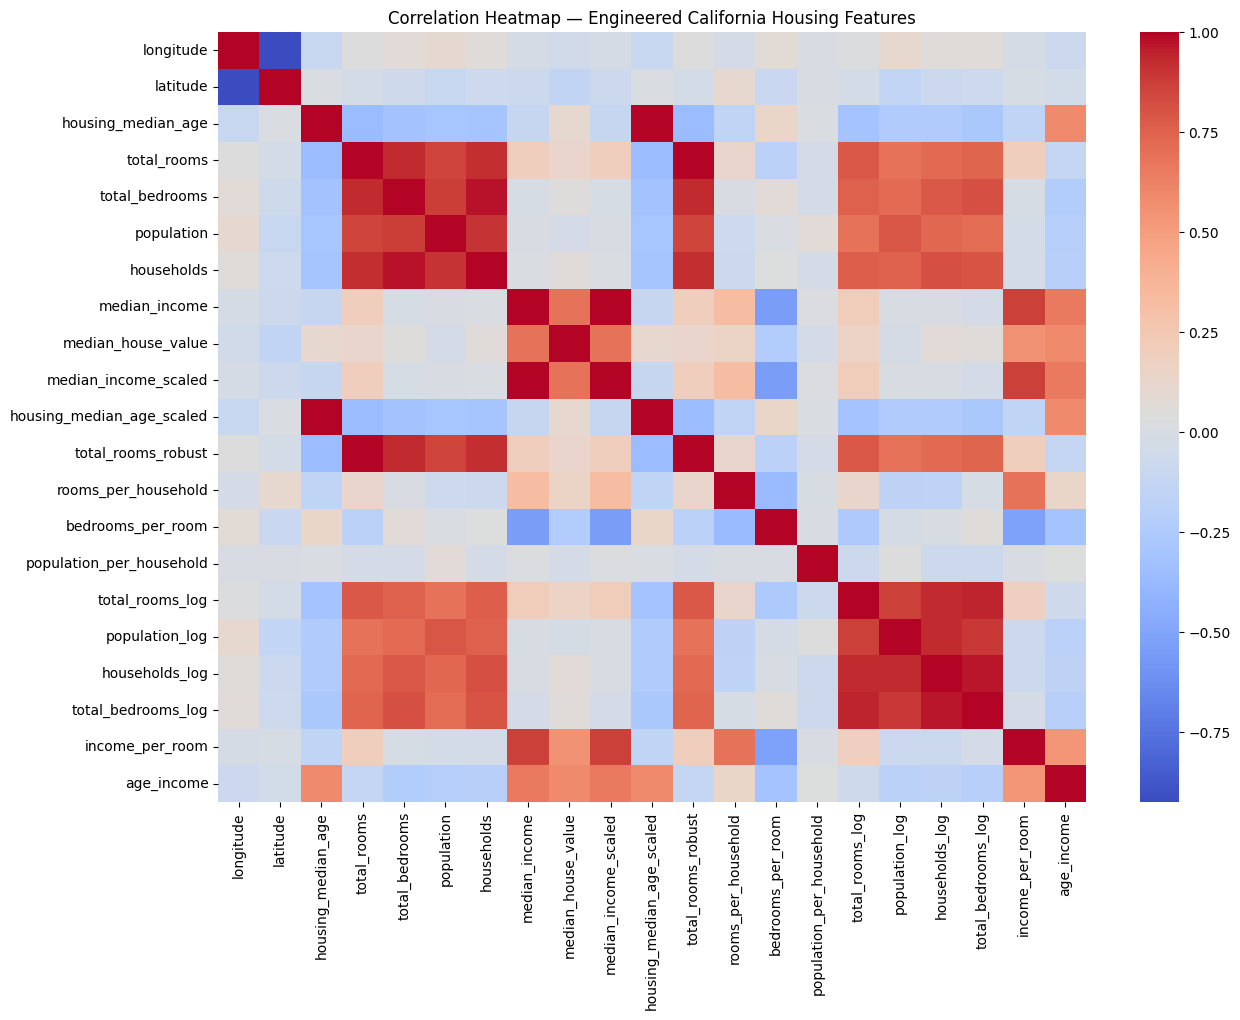

,median_house_value
median_house_value,1.000000
median_income,0.688075
median_income_scaled,0.688075
age_income,0.589142
income_per_room,0.555438
total_rooms_log,0.159422
rooms_per_household,0.151948
total_rooms_robust,0.134153
total_rooms,0.134153
housing_median_age,0.105623


In [ ]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm")
plt.title("Correlation Heatmap — Engineered California Housing Features")
plt.show()
corr["median_house_value"].sort_values(ascending=False)

In [ ]:
drop_cols = ["age_group"]  # categorical bin, not numeric
X = df.drop(columns=["median_house_value"] + drop_cols).select_dtypes(include=np.number)
y = df["median_house_value"]
print("Total engineered features available:", X.shape[1])
X.columns.tolist()

Total engineered features available: 20


['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_income_scaled',
 'housing_median_age_scaled',
 'total_rooms_robust',
 'rooms_per_household',
 'bedrooms_per_room',
 'population_per_household',
 'total_rooms_log',
 'population_log',
 'households_log',
 'total_bedrooms_log',
 'income_per_room',
 'age_income']

In [ ]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import MinMaxScaler as MMS
X_scaled_for_var = pd.DataFrame(MMS().fit_transform(X), columns=X.columns)
selector = VarianceThreshold(threshold=0.01)
X_selected = selector.fit_transform(X_scaled_for_var)
selected_features = X.columns[selector.get_support()]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 14
Remaining Features: 6

Remaining Features
['longitude', 'latitude', 'housing_median_age', 'median_income', 'median_income_scaled', 'housing_median_age_scaled']


In [ ]:
corr_matrix = X.corr().abs()
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
X_selected = X.drop(columns=to_drop)
print("Original Features :", X.shape[1])
print("Removed Features  :", len(to_drop))
print("Remaining Features:", X_selected.shape[1])
print("\nDropped Features (correlation > 0.95)")
print(to_drop)

Original Features : 20
Removed Features  : 5
Remaining Features: 15

Dropped Features (correlation > 0.95)
['households', 'median_income_scaled', 'housing_median_age_scaled', 'total_rooms_robust', 'total_bedrooms_log']


In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression
selector = SelectKBest(score_func=f_regression, k=10)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 10
Remaining Features: 10

Remaining Features
['latitude', 'total_rooms', 'median_income', 'median_income_scaled', 'total_rooms_robust', 'rooms_per_household', 'bedrooms_per_room', 'total_rooms_log', 'income_per_room', 'age_income']


In [ ]:
from sklearn.feature_selection import mutual_info_regression
selector = SelectKBest(mutual_info_regression, k=10)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 10
Remaining Features: 10

Remaining Features
['longitude', 'latitude', 'median_income', 'median_income_scaled', 'total_rooms_robust', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_room', 'age_income']


In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
model = LinearRegression()
selector = RFE(model, n_features_to_select=10)
selector.fit(X, y)
selected_features = X.columns[selector.support_]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 10
Remaining Features: 10

Remaining Features
['longitude', 'latitude', 'median_income', 'median_income_scaled', 'rooms_per_household', 'bedrooms_per_room', 'total_rooms_log', 'population_log', 'households_log', 'total_bedrooms_log']


Original Features : 20
Removed Features  : 10
Remaining Features: 10

Remaining Features
['median_income', 'median_income_scaled', 'population_per_household', 'latitude', 'longitude', 'age_income', 'rooms_per_household', 'bedrooms_per_room', 'income_per_room', 'population_log']


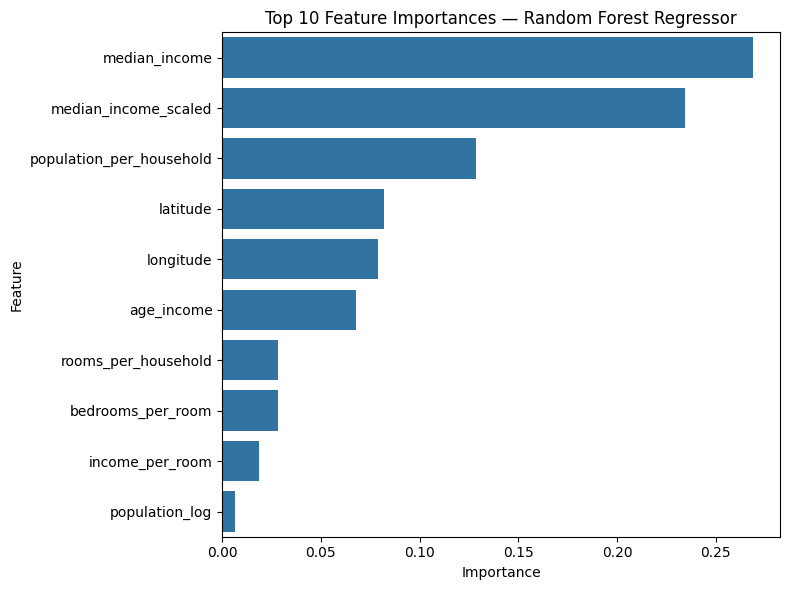

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(random_state=42, n_estimators=100, n_jobs=-1)
model.fit(X, y)
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})
importance = importance.sort_values(by="Importance", ascending=False)
selected_features = importance.head(10)["Feature"]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())
plt.figure(figsize=(8, 6))
sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Feature Importances — Random Forest Regressor")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler as SS
X_std = pd.DataFrame(SS().fit_transform(X), columns=X.columns)
model = Lasso(alpha=100)
model.fit(X_std, y)
coef = pd.Series(model.coef_, index=X.columns)
selected_features = coef[coef != 0].index
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 3
Remaining Features: 17

Remaining Features
['longitude', 'latitude', 'housing_median_age', 'population', 'households', 'median_income', 'housing_median_age_scaled', 'total_rooms_robust', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'total_rooms_log', 'population_log', 'households_log', 'total_bedrooms_log', 'income_per_room', 'age_income']


In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector
model = LinearRegression()
selector = SequentialFeatureSelector(
    model,
    n_features_to_select=10,
    direction="forward",
    n_jobs=-1
)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 10
Remaining Features: 10

Remaining Features
['housing_median_age', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'total_rooms_log', 'population_log', 'households_log', 'total_bedrooms_log', 'income_per_room']


In [ ]:
from sklearn.feature_selection import SelectFromModel
model = RandomForestRegressor(random_state=42, n_estimators=100, n_jobs=-1)
selector = SelectFromModel(model)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]
print("Original Features :", X.shape[1])
print("Removed Features  :", X.shape[1] - len(selected_features))
print("Remaining Features:", len(selected_features))
print("\nRemaining Features")
print(selected_features.tolist())

Original Features : 20
Removed Features  : 14
Remaining Features: 6

Remaining Features
['longitude', 'latitude', 'median_income', 'median_income_scaled', 'population_per_household', 'age_income']


In [ ]:
summary = pd.DataFrame({
    "Feature Selection Technique": [
        "Variance Threshold (threshold=0.01)",
        "Correlation Filter (correlation > 0.95)",
        "SelectKBest (f_regression, k=10)",
        "Mutual Information (k=10)",
        "Recursive Feature Elimination (RFE, n_features_to_select=10)",
        "Random Forest Feature Importance (Top 10)",
        "Lasso (L1 Regularization)",
        "Sequential Feature Selector (n_features_to_select=10)",
        "SelectFromModel"
    ],
    "Original Features": [X.shape[1]] * 9,
    "Remaining Features": [
        "Depends on threshold",
        "Depends on the data",
        10, 10, 10, 10,
        "Depends on regularization strength",
        10,
        "Depends on the importance threshold"
    ]
})
summary

,Feature Selection Technique,Original Features,Remaining Features
0,Variance Threshold (threshold=0.01),20,Depends on threshold
1,Correlation Filter (correlation > 0.95),20,Depends on the data
2,"SelectKBest (f_regression, k=10)",20,10
3,Mutual Information (k=10),20,10
4,"Recursive Feature Elimination (RFE, n_features...",20,10
5,Random Forest Feature Importance (Top 10),20,10
6,Lasso (L1 Regularization),20,Depends on regularization strength
7,Sequential Feature Selector (n_features_to_sel...,20,10
8,SelectFromModel,20,Depends on the importance threshold
